# Machine Maintenance Insight — DS Sprint Use Case 25
## Complete end-to-end Google Colab project

This notebook generates five **synthetic educational datasets**, cleans them, performs EDA, engineers features, trains/evaluates a machine-learning model, creates a machine-priority ranking, exports an Excel workbook, and prepares outputs for GitHub.

**Important:** This is simulated data, not real industrial data. The target label is a simulated future urgent-maintenance event. Metrics demonstrate the workflow only and must not be claimed as real-world predictive performance. If your instructor supplies actual data, use that instead.

## 0. Setup
Run all cells from top to bottom in Google Colab. The notebook creates its own folders.

In [1]:
import os, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, roc_auc_score, RocCurveDisplay
warnings.filterwarnings("ignore")

SEED = 42
rng = np.random.default_rng(SEED)
PROJECT = Path("/content/machine_maintenance_insight")
DATA = PROJECT / "data"
OUT = PROJECT / "outputs"
DATA.mkdir(parents=True, exist_ok=True)
OUT.mkdir(parents=True, exist_ok=True)
print("Project directory:", PROJECT)

Project directory: /content/machine_maintenance_insight


## 1. Generate five related synthetic datasets

We simulate 40 machines, 30 days of sensor and usage data, historical maintenance records, and a separate 15-day future outcome window. Latent susceptibility is used only to generate the simulation and is never included as a model feature.

In [2]:
N = 40
OBS_DAYS = 30
FUTURE_DAYS = 15
machines_ids = [f"M{i:03d}" for i in range(1, N + 1)]
start = pd.Timestamp("2026-01-01")
obs_end = start + pd.Timedelta(days=OBS_DAYS)
future_end = obs_end + pd.Timedelta(days=FUTURE_DAYS)

machines = pd.DataFrame({
    "machine": machines_ids,
    "type": rng.choice(["Motor", "Pump", "Compressor"], N),
    "age": rng.integers(1, 16, N),
    "installation_date": pd.to_datetime("2021-01-01") -
        pd.to_timedelta(rng.integers(0, 1800, N), unit="D")
})
susceptibility = {m: min(float(rng.beta(2, 4) + (0.25 if i < 8 else 0)), 0.98)
                  for i, m in enumerate(machines_ids)}

# Sensor data: 4 readings/day/machine
sensor_rows = []
for m in machines_ids:
    sus = susceptibility[m]
    for ts in pd.date_range(start, periods=OBS_DAYS * 4, freq="6h"):
        progress = (ts - start).total_seconds() / 86400 / OBS_DAYS
        sensor_rows.append({
            "timestamp": ts, "machine": m,
            "vibration": max(0.1, rng.normal(3.2 + 3.0*sus + 0.3*progress, 0.65)),
            "temperature": rng.normal(49 + 18*sus + 2*progress, 4.0),
            "current": max(0.1, rng.normal(10 + 3*sus, 1.1))
        })
sensor = pd.DataFrame(sensor_rows)

# Daily usage data
usage_rows = []
for m in machines_ids:
    sus = susceptibility[m]
    for day in pd.date_range(start, periods=OBS_DAYS, freq="D"):
        load = np.clip(rng.normal(55 + 32*sus, 10), 15, 100)
        runtime = np.clip(rng.normal(12 + 8*sus, 3), 1, 24)
        usage_rows.append({
            "date": day, "machine": m, "runtime": round(float(runtime), 2),
            "load": round(float(load), 2),
            "cycles": int(max(0, runtime * rng.normal(55 + 12*sus, 8)))
        })
usage = pd.DataFrame(usage_rows)

# Alarm events
alarm_rows = []
for r in sensor.itertuples(index=False):
    if r.vibration > 5.8 and rng.random() < 0.75:
        alarm_rows.append({"machine": r.machine, "timestamp": r.timestamp,
                           "alarm_type": rng.choice(["High Vibration", "high vibration"])})
    if r.temperature > 72 and rng.random() < 0.65:
        alarm_rows.append({"machine": r.machine, "timestamp": r.timestamp,
                           "alarm_type": "High Temperature"})
    if rng.random() < 0.012:
        alarm_rows.append({"machine": r.machine, "timestamp": r.timestamp,
                           "alarm_type": "Load Warning"})
alarms = pd.DataFrame(alarm_rows, columns=["machine", "timestamp", "alarm_type"])

# Historical maintenance before the observation window
maintenance_rows = []
for m in machines_ids:
    sus = susceptibility[m]
    for _ in range(int(rng.poisson(0.7 + 2*sus))):
        maintenance_rows.append({
            "machine": m,
            "service_date": start - pd.Timedelta(days=int(rng.integers(1, 365))),
            "action": rng.choice(["Inspection", "Lubrication", "Calibration", "Part Replacement"]),
            "downtime": round(float(max(0.5, rng.gamma(2, 1.2 + 2*sus))), 2),
            "record_period": "historical"
        })

# Future urgent repair events: used only to create the target label
future_rows = []
for m in machines_ids:
    p = 0.08 + 0.78 * susceptibility[m]
    if rng.random() < p:
        future_rows.append({
            "machine": m,
            "service_date": obs_end + pd.Timedelta(days=int(rng.integers(0, FUTURE_DAYS))),
            "action": "Urgent Repair",
            "downtime": round(float(rng.uniform(4, 18)), 2),
            "record_period": "future_outcome"
        })
maintenance = pd.DataFrame(maintenance_rows + future_rows)

# Add small data-quality issues for practice
for col in ["vibration", "temperature", "current"]:
    ix = rng.choice(sensor.index, size=12, replace=False)
    sensor.loc[ix, col] = np.nan
ix = rng.choice(usage.index, size=6, replace=False)
usage.loc[ix, "load"] = np.nan
sensor = pd.concat([sensor, sensor.sample(8, random_state=SEED)], ignore_index=True)

raw = {
    "machines.csv": machines, "sensor.csv": sensor, "usage.csv": usage,
    "alarms.csv": alarms, "maintenance.csv": maintenance
}
for name, df in raw.items():
    df.to_csv(DATA / name, index=False)
    print(f"{name:18} rows={len(df):5} columns={len(df.columns)}")
print("Observation window:", start.date(), "to", (obs_end - pd.Timedelta(days=1)).date())
print("Future outcome window:", obs_end.date(), "to", (future_end - pd.Timedelta(days=1)).date())

machines.csv       rows=   40 columns=4
sensor.csv         rows= 4808 columns=5
usage.csv          rows= 1200 columns=5
alarms.csv         rows=  301 columns=3
maintenance.csv    rows=   67 columns=5
Observation window: 2026-01-01 to 2026-01-30
Future outcome window: 2026-01-31 to 2026-02-14


## 2. Inspect the raw data

Review row counts, columns, types, missing values, duplicate records, alarm labels, and summary statistics. These outputs provide evidence for the data-preparation section of the assessment sheet.

In [3]:
for name, df in raw.items():
    print("\\n", name, "| shape:", df.shape)
    display(df.head(3))
    display(pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing": df.isna().sum(),
        "missing_percent": (df.isna().mean()*100).round(2)
    }))
print("Duplicate machine-timestamp pairs in sensor data:",
      sensor.duplicated(["machine", "timestamp"]).sum())
display(alarms["alarm_type"].value_counts(dropna=False))
display(sensor[["vibration", "temperature", "current"]].describe().T)

\n machines.csv | shape: (40, 4)


,machine,type,age,installation_date
0,M001,Motor,3,2016-05-15
1,M002,Compressor,12,2018-11-07
2,M003,Pump,11,2020-03-18


,dtype,missing,missing_percent
machine,object,0,0.0
type,object,0,0.0
age,int64,0,0.0
installation_date,datetime64[ns],0,0.0


\n sensor.csv | shape: (4808, 5)


,timestamp,machine,vibration,temperature,current
0,2026-01-01 00:00:00,M001,5.427051,65.613247,11.707320
1,2026-01-01 06:00:00,M001,4.627413,59.384886,12.144022
2,2026-01-01 12:00:00,M001,5.197048,55.959436,11.976815


...

,machine,service_date,action,downtime,record_period
0,M001,2025-07-26,Lubrication,7.45,historical
1,M001,2025-10-10,Calibration,5.05,historical
2,M001,2025-07-25,Part Replacement,1.64,historical


,dtype,missing,missing_percent
machine,object,0,0.0
service_date,datetime64[ns],0,0.0
action,object,0,0.0
downtime,float64,0,0.0
record_period,object,0,0.0


Duplicate machine-timestamp pairs in sensor data: 8


,count
alarm_type,
high vibration,121
High Vibration,108
Load Warning,67
High Temperature,5


,count,mean,std,min,25%,50%,75%,max
vibration,4796.0,4.517097,0.870725,1.420550,3.904388,4.551308,5.121368,7.657298
temperature,4796.0,56.990262,5.320228,39.769518,53.229946,57.160249,60.696555,73.159949
current,4796.0,11.126389,1.228116,7.157825,10.266478,11.126530,11.983549,15.592344


## 3. Clean data

We parse date columns, remove duplicate machine/timestamp sensor rows, normalize alarm labels, impute missing numeric values with medians, and flag—not automatically delete—potential outliers using the IQR rule. Extreme sensor readings may be meaningful, so they should be investigated rather than removed blindly.

In [4]:
sensor_c = sensor.copy()
machines_c = machines.copy()
usage_c = usage.copy()
alarms_c = alarms.copy()
maintenance_c = maintenance.copy()

sensor_c["timestamp"] = pd.to_datetime(sensor_c["timestamp"], errors="coerce")
sensor_c = sensor_c.dropna(subset=["timestamp", "machine"])
sensor_c = sensor_c.drop_duplicates(["machine", "timestamp"], keep="first").copy()
for col in ["vibration", "temperature", "current"]:
    sensor_c[col] = pd.to_numeric(sensor_c[col], errors="coerce")
    sensor_c[col] = sensor_c[col].fillna(sensor_c[col].median())

machines_c["installation_date"] = pd.to_datetime(machines_c["installation_date"], errors="coerce")
usage_c["date"] = pd.to_datetime(usage_c["date"], errors="coerce")
for col in ["runtime", "load", "cycles"]:
    usage_c[col] = pd.to_numeric(usage_c[col], errors="coerce")
    usage_c[col] = usage_c[col].fillna(usage_c[col].median())

alarms_c["timestamp"] = pd.to_datetime(alarms_c["timestamp"], errors="coerce")
alarms_c["alarm_type"] = alarms_c["alarm_type"].astype("string").str.strip().str.lower()
label_map = {"high vibration": "High Vibration",
             "high temperature": "High Temperature",
             "load warning": "Load Warning"}
alarms_c["alarm_type"] = alarms_c["alarm_type"].map(label_map).fillna(
    alarms_c["alarm_type"].str.title())
alarms_c = alarms_c.dropna(subset=["machine", "timestamp", "alarm_type"])

maintenance_c["service_date"] = pd.to_datetime(maintenance_c["service_date"], errors="coerce")
maintenance_c["downtime"] = pd.to_numeric(maintenance_c["downtime"], errors="coerce")
maintenance_c["downtime"] = maintenance_c["downtime"].fillna(maintenance_c["downtime"].median())

outlier_rows = []
for col in ["vibration", "temperature", "current"]:
    q1, q3 = sensor_c[col].quantile([0.25, 0.75])
    iqr = q3-q1
    lo, hi = q1-1.5*iqr, q3+1.5*iqr
    flag = (sensor_c[col] < lo) | (sensor_c[col] > hi)
    outlier_rows.append({"feature": col, "lower_bound": lo, "upper_bound": hi,
                         "potential_outliers": int(flag.sum())})
print("Sensor rows before:", len(sensor), "| after:", len(sensor_c))
print("Missing values remaining in key sensor fields:",
      int(sensor_c[["vibration","temperature","current"]].isna().sum().sum()))
display(pd.DataFrame(outlier_rows))
display(alarms_c["alarm_type"].value_counts().rename_axis("alarm_type").reset_index(name="count"))

Sensor rows before: 4808 | after: 4800
Missing values remaining in key sensor fields: 0


,feature,lower_bound,upper_bound,potential_outliers
0,vibration,2.082258,6.944269,22
1,temperature,42.047880,71.879681,17
2,current,7.703900,14.544850,21


,alarm_type,count
0,High Vibration,229
1,Load Warning,67
2,High Temperature,5


## 4. Exploratory data analysis (EDA)

Charts cover sensor distributions, time trends, alarm frequency, load versus historical downtime, machine-type comparisons, and repeated service patterns.

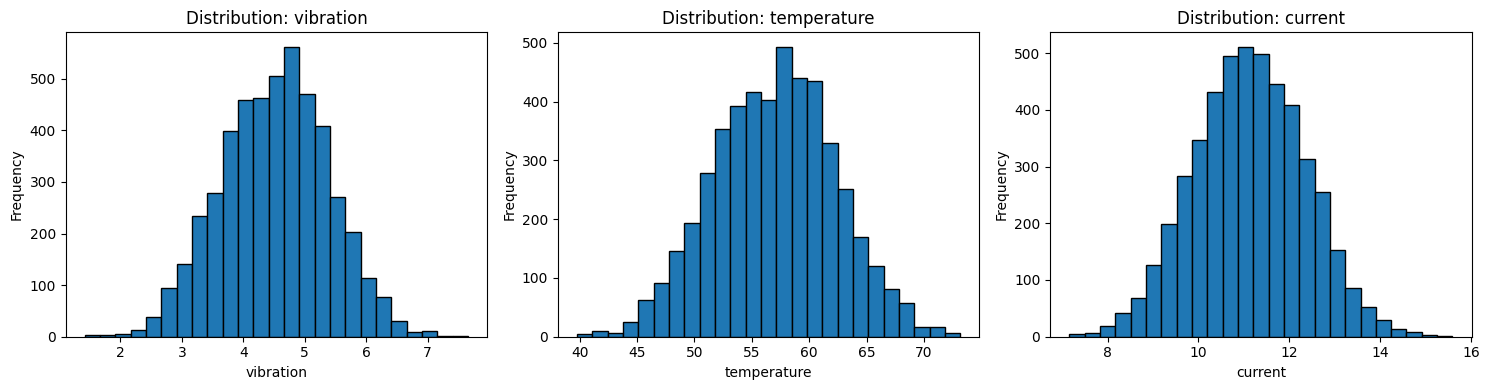

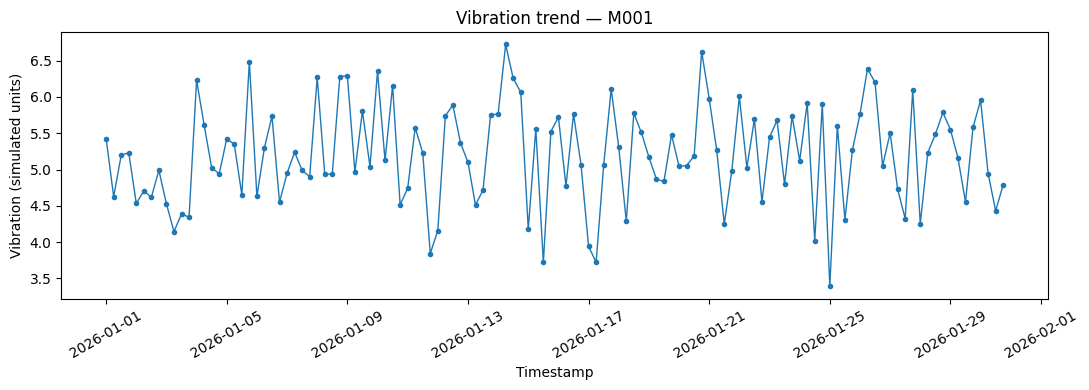

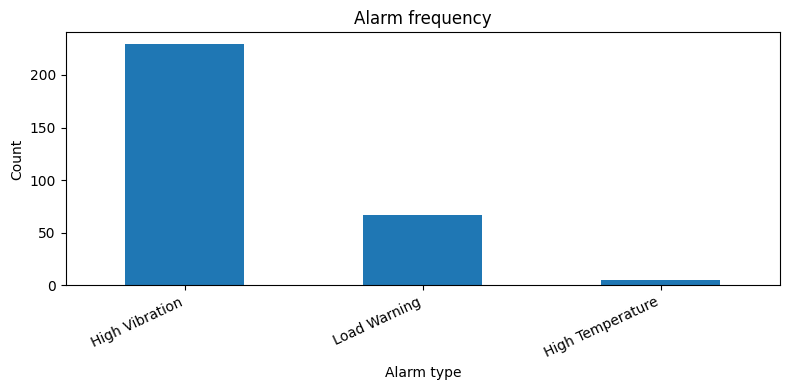

,alarm_type,alarm_count
0,High Vibration,229
1,Load Warning,67
2,High Temperature,5


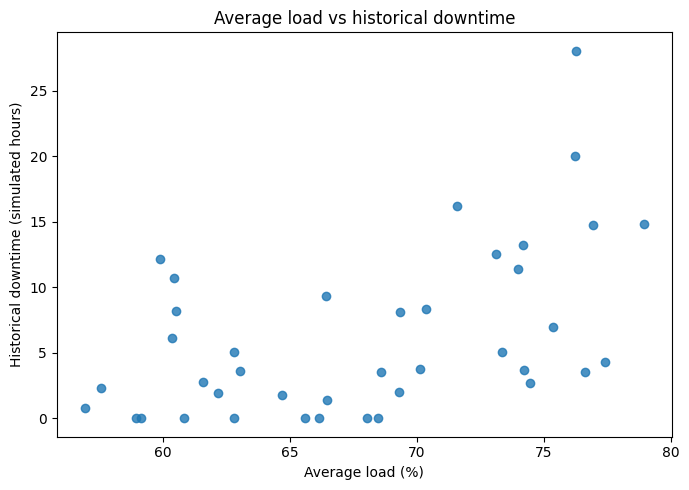

Correlation: 0.505


,type,machine_count,mean_load,mean_historical_downtime,mean_historical_services
0,Compressor,15,68.389089,6.859333,1.066667
1,Motor,10,68.892567,8.214000,2.000000
2,Pump,15,66.563533,4.272000,1.000000


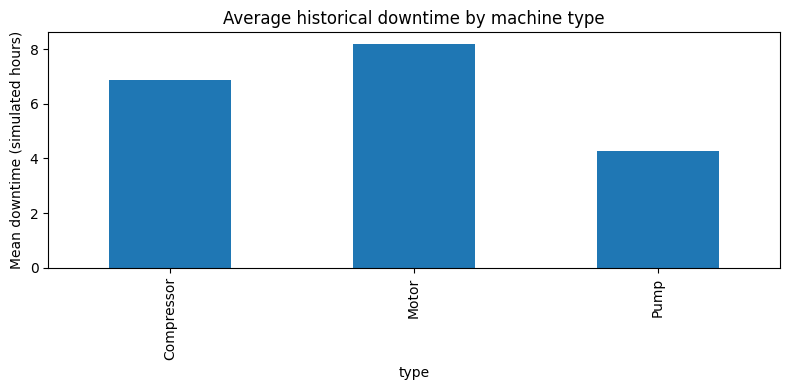

,machine,historical_service_count
0,M001,6
1,M006,3
2,M007,3
3,M002,2
4,M009,2
5,M010,2
6,M018,2
7,M011,2
8,M019,2
9,M028,2


In [5]:
# Sensor distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["vibration", "temperature", "current"]):
    ax.hist(sensor_c[col], bins=25, edgecolor="black")
    ax.set_title(f"Distribution: {col}")
    ax.set_xlabel(col); ax.set_ylabel("Frequency")
plt.tight_layout(); plt.show()

# Example machine sensor trend
example_id = machines_ids[0]
d = sensor_c[sensor_c["machine"] == example_id].sort_values("timestamp")
plt.figure(figsize=(11, 4))
plt.plot(d["timestamp"], d["vibration"], marker=".", linewidth=1)
plt.title(f"Vibration trend — {example_id}")
plt.xlabel("Timestamp"); plt.ylabel("Vibration (simulated units)")
plt.xticks(rotation=30); plt.tight_layout(); plt.show()

# Alarm frequency
alarm_counts = alarms_c["alarm_type"].value_counts()
alarm_counts.plot(kind="bar", figsize=(8, 4), title="Alarm frequency")
plt.xlabel("Alarm type"); plt.ylabel("Count"); plt.xticks(rotation=25, ha="right")
plt.tight_layout(); plt.show()
display(alarm_counts.rename_axis("alarm_type").reset_index(name="alarm_count"))

# Usage vs historical downtime; only historical records, no future outcomes
historical = maintenance_c[(maintenance_c["record_period"] == "historical") &
                           (maintenance_c["service_date"] < start)].copy()
usage_features0 = usage_c.groupby("machine", as_index=False).agg(
    average_load=("load", "mean"), average_runtime=("runtime", "mean"),
    total_cycles=("cycles", "sum"))
hist_features0 = historical.groupby("machine", as_index=False).agg(
    historical_downtime=("downtime", "sum"),
    historical_service_count=("service_date", "count"))
load_down = usage_features0.merge(hist_features0, on="machine", how="left").fillna(0)
plt.figure(figsize=(7, 5))
plt.scatter(load_down["average_load"], load_down["historical_downtime"], alpha=.8)
plt.title("Average load vs historical downtime")
plt.xlabel("Average load (%)"); plt.ylabel("Historical downtime (simulated hours)")
plt.tight_layout(); plt.show()
print("Correlation:", round(load_down["average_load"].corr(load_down["historical_downtime"]), 3))

# Machine-type comparison
type_comparison = machines_c.merge(load_down, on="machine", how="left").groupby(
    "type", as_index=False).agg(
    machine_count=("machine", "nunique"),
    mean_load=("average_load", "mean"),
    mean_historical_downtime=("historical_downtime", "mean"),
    mean_historical_services=("historical_service_count", "mean"))
display(type_comparison)
type_comparison.plot(x="type", y="mean_historical_downtime", kind="bar",
                     legend=False, figsize=(8, 4),
                     title="Average historical downtime by machine type")
plt.ylabel("Mean downtime (simulated hours)"); plt.tight_layout(); plt.show()

# Repeat-service patterns
display(historical.groupby("machine").size().sort_values(ascending=False)
        .head(10).rename("historical_service_count").reset_index())

## 5. Feature engineering and target label

Features are aggregated from the observation period only. The target is whether the synthetic records contain an urgent repair in the following 15-day window. Future maintenance records are not used as input features, preventing direct future-outcome leakage.

In [6]:
sensor_obs = sensor_c[(sensor_c["timestamp"] >= start) &
                      (sensor_c["timestamp"] < obs_end)]
sensor_f = sensor_obs.groupby("machine", as_index=False).agg(
    mean_vibration=("vibration", "mean"), max_vibration=("vibration", "max"),
    std_vibration=("vibration", "std"), mean_temperature=("temperature", "mean"),
    max_temperature=("temperature", "max"), mean_current=("current", "mean"),
    max_current=("current", "max"), sensor_record_count=("timestamp", "count"))

usage_obs = usage_c[(usage_c["date"] >= start) & (usage_c["date"] < obs_end)]
usage_f = usage_obs.groupby("machine", as_index=False).agg(
    mean_load=("load", "mean"), max_load=("load", "max"),
    mean_runtime=("runtime", "mean"), total_runtime=("runtime", "sum"),
    total_cycles=("cycles", "sum"))

alarms_obs = alarms_c[(alarms_c["timestamp"] >= start) &
                      (alarms_c["timestamp"] < obs_end)]
alarm_f = pd.crosstab(alarms_obs["machine"], alarms_obs["alarm_type"]).reset_index()
alarm_f.columns = ["machine" if c == "machine" else
                   "alarm_count_" + str(c).lower().replace(" ", "_")
                   for c in alarm_f.columns]
if "machine" not in alarm_f.columns:
    alarm_f = pd.DataFrame({"machine": machines_ids})
alarm_f["total_alarm_count"] = alarm_f.drop(columns="machine").sum(axis=1)

hist_f = historical.groupby("machine", as_index=False).agg(
    historical_service_count=("service_date", "count"),
    historical_downtime=("downtime", "sum"),
    historical_mean_downtime=("downtime", "mean"))

features = (machines_c[["machine", "type", "age"]]
    .merge(sensor_f, on="machine", how="left")
    .merge(usage_f, on="machine", how="left")
    .merge(alarm_f, on="machine", how="left")
    .merge(hist_f, on="machine", how="left"))

for col in [c for c in features.columns if "count" in c or c == "total_alarm_count"]:
    features[col] = features[col].fillna(0)
for col in ["historical_downtime", "historical_mean_downtime"]:
    features[col] = features[col].fillna(0)

future_events = maintenance_c[(maintenance_c["record_period"] == "future_outcome") &
                               (maintenance_c["service_date"] >= obs_end) &
                               (maintenance_c["service_date"] < future_end)]
target = pd.DataFrame({"machine": machines_ids})
target["maintenance_needed"] = target["machine"].isin(
    future_events["machine"].unique()).astype(int)

model_data = features.merge(target, on="machine", how="left")
print("Feature table shape:", features.shape)
print("Target distribution:")
display(model_data["maintenance_needed"].value_counts()
        .rename_axis("maintenance_needed").reset_index(name="machine_count"))
display(model_data.head())

Feature table shape: (40, 23)
Target distribution:


,maintenance_needed,machine_count
0,0,24
1,1,16


,machine,type,age,mean_vibration,max_vibration,std_vibration,mean_temperature,max_temperature,mean_current,max_current,...,total_runtime,total_cycles,alarm_count_high_temperature,alarm_count_high_vibration,alarm_count_load_warning,total_alarm_count,historical_service_count,historical_downtime,historical_mean_downtime,maintenance_needed
0,M001,Motor,3,5.198642,6.722750,0.687487,60.946768,70.383551,11.955999,15.072850,...,522.39,32564,0.0,17.0,1.0,18.0,6.0,28.05,4.675,1
1,M002,Compressor,12,4.888509,7.039182,0.702452,59.232338,68.784876,11.390120,13.814255,...,479.70,29472,0.0,6.0,1.0,7.0,2.0,11.42,5.710,0
2,M003,Pump,11,4.669383,6.445647,0.651155,57.765158,66.776996,11.310150,14.005326,...,442.40,26464,0.0,6.0,5.0,11.0,1.0,1.99,1.990,1
3,M004,Pump,6,4.609777,6.310618,0.743919,57.517490,66.963492,11.277739,14.519303,...,452.34,26196,0.0,6.0,1.0,7.0,0.0,0.00,0.000,1
4,M005,Pump,2,5.161080,6.394575,0.601677,61.479504,71.272568,11.623977,15.009852,...,531.93,33823,0.0,15.0,3.0,18.0,1.0,2.68,2.680,0


## 6. Machine learning: Random Forest classifier

We predict the simulated binary future outcome. Numeric and categorical preprocessing is kept inside a scikit-learn pipeline to avoid fitting preprocessing on the test set. The small synthetic sample means test metrics are unstable and only demonstrate the evaluation process.

Class counts:


,class,count
0,0,24
1,1,16


,Metric,Value
0,Accuracy,0.4000
1,Precision,0.3333
2,Recall,0.5000
3,F1-score,0.4000
4,ROC-AUC,0.5417


              precision    recall  f1-score   support

           0       0.50      0.33      0.40         6
           1       0.33      0.50      0.40         4

    accuracy                           0.40        10
   macro avg       0.42      0.42      0.40        10
weighted avg       0.43      0.40      0.40        10



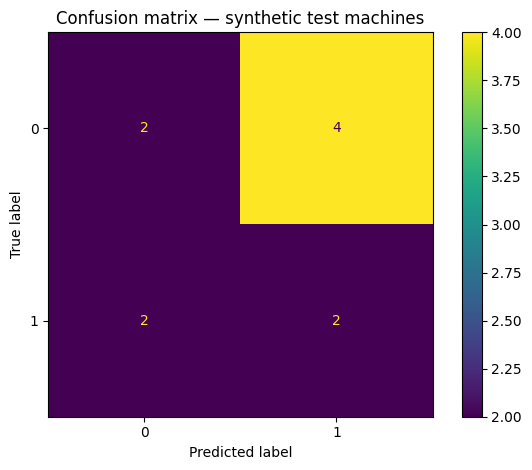

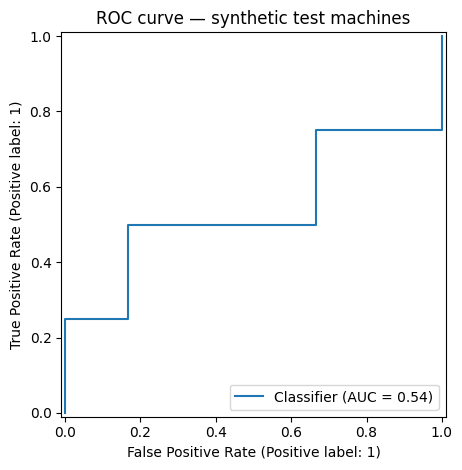

Majority-class baseline accuracy: 0.6


In [7]:
target_col = "maintenance_needed"
X = model_data.drop(columns=["machine", target_col])
y = model_data[target_col].astype(int)
print("Class counts:")
display(y.value_counts().rename_axis("class").reset_index(name="count"))

model = None
metrics_df = pd.DataFrame()
if y.nunique() < 2 or y.value_counts().min() < 2:
    print("Insufficient examples in both classes for stratified evaluation. Rerun with a larger simulation.")
else:
    numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=["number"]).columns.tolist()
    try:
        enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        enc = OneHotEncoder(handle_unknown="ignore", sparse=False)

    pre = ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), numeric_cols),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("encode", enc)]), categorical_cols)
    ])
    model = Pipeline([
        ("preprocess", pre),
        ("classifier", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                               class_weight="balanced",
                                               random_state=SEED))
    ])
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=.25, random_state=SEED, stratify=y)
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    prob = model.predict_proba(X_test)[:, 1]
    values = {
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0)
    }
    if y_test.nunique() == 2:
        values["ROC-AUC"] = roc_auc_score(y_test, prob)
    metrics_df = pd.DataFrame([{"Metric": k, "Value": round(float(v), 4)}
                               for k, v in values.items()])
    display(metrics_df)
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred)
    plt.title("Confusion matrix — synthetic test machines")
    plt.tight_layout(); plt.show()
    if y_test.nunique() == 2:
        RocCurveDisplay.from_predictions(y_test, prob)
        plt.title("ROC curve — synthetic test machines")
        plt.tight_layout(); plt.show()

    baseline = DummyClassifier(strategy="most_frequent")
    baseline.fit(X_train, y_train)
    print("Majority-class baseline accuracy:",
          round(accuracy_score(y_test, baseline.predict(X_test)), 4))

## 7. Feature importance and maintenance-priority ranking

Feature importance describes model usage, not causation. The priority score below combines percentile ranks for maximum vibration, maximum temperature, alarm count and historical downtime. It is a transparent screening aid, not an engineering diagnosis.

,machine,type,age,mean_vibration,max_vibration,mean_temperature,max_temperature,total_alarm_count,historical_service_count,historical_downtime,maintenance_needed,vibration_rank,temperature_rank,alarm_rank,downtime_rank,priority_score,priority_level
15,M016,Compressor,1,5.510224,7.657298,63.077324,72.847051,28.0,1.0,14.72,0,1.000,0.975,0.9750,0.9000,0.967500,High
36,M037,Compressor,5,5.329780,7.145200,61.627631,73.159949,29.0,1.0,4.31,1,0.975,1.000,1.0000,0.5500,0.902500,High
5,M006,Compressor,15,5.211395,6.987773,60.874317,71.847379,11.0,3.0,20.03,1,0.900,0.900,0.7750,0.9750,0.883750,High
6,M007,Motor,7,5.357488,6.948572,61.742696,70.110017,26.0,3.0,14.83,1,0.850,0.725,0.9500,0.9250,0.858750,High
0,M001,Motor,3,5.198642,6.722750,60.946768,70.383551,18.0,6.0,28.05,1,0.750,0.775,0.9125,1.0000,0.846875,High
17,M018,Motor,3,5.218267,6.882343,61.713732,72.436234,15.0,2.0,6.95,0,0.800,0.950,0.8500,0.6500,0.820000,High
20,M021,Pump,14,5.051531,7.012326,59.483676,69.089803,9.0,2.0,16.23,1,0.925,0.650,0.6875,0.9500,0.801875,High
26,M027,Pump,14,4.951076,6.987028,59.835217,70.711367,11.0,2.0,5.05,0,0.875,0.800,0.7750,0.5875,0.773750,High
1,M002,Compressor,12,4.888509,7.039182,59.232338,68.784876,7.0,2.0,11.42,0,0.950,0.600,0.6125,0.8000,0.748125,Medium
32,M033,Motor,7,5.022191,6.901965,59.631121,70.940934,9.0,1.0,3.67,1,0.825,0.825,0.6875,0.5000,0.725625,Medium


,feature,importance
7,num__max_current,0.116265
4,num__mean_temperature,0.101046
1,num__mean_vibration,0.085003
6,num__mean_current,0.080031
12,num__total_runtime,0.068202
17,num__total_alarm_count,0.063767
11,num__mean_runtime,0.062014
5,num__max_temperature,0.059612
13,num__total_cycles,0.050664
9,num__mean_load,0.049783


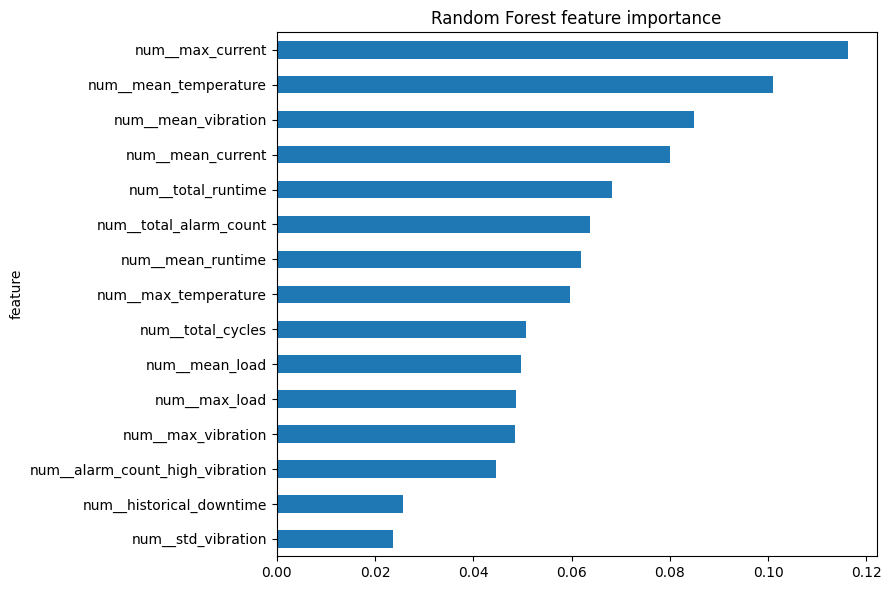

In [8]:
priority = model_data[[
    "machine", "type", "age", "mean_vibration", "max_vibration",
    "mean_temperature", "max_temperature", "total_alarm_count",
    "historical_service_count", "historical_downtime", "maintenance_needed"
]].copy()

def rank01(s):
    return s.rank(pct=True).fillna(0)

priority["vibration_rank"] = rank01(priority["max_vibration"])
priority["temperature_rank"] = rank01(priority["max_temperature"])
priority["alarm_rank"] = rank01(priority["total_alarm_count"])
priority["downtime_rank"] = rank01(priority["historical_downtime"])
priority["priority_score"] = (
    .30*priority["vibration_rank"] + .25*priority["temperature_rank"] +
    .25*priority["alarm_rank"] + .20*priority["downtime_rank"])
priority["priority_level"] = pd.cut(
    priority["priority_score"], [-.001, .50, .75, 1.001],
    labels=["Low", "Medium", "High"])
priority = priority.sort_values("priority_score", ascending=False)
display(priority.head(15))

if model is not None:
    try:
        names = model.named_steps["preprocess"].get_feature_names_out()
        importances = model.named_steps["classifier"].feature_importances_
        importance_df = pd.DataFrame({"feature": names, "importance": importances})
        importance_df = importance_df.sort_values("importance", ascending=False).head(15)
        display(importance_df)
        importance_df.sort_values("importance").plot(
            x="feature", y="importance", kind="barh", legend=False, figsize=(9, 6))
        plt.title("Random Forest feature importance")
        plt.tight_layout(); plt.show()
    except Exception as err:
        print("Feature importance extraction issue:", err)

## 8. Findings and recommendations

The next cell prints actual findings from this generated run. Use the values displayed by your run if you fill in your assessment sheet. Label them as **synthetic-data findings**.

In [9]:
print("SYNTHETIC DATA ONLY — NOT REAL INDUSTRIAL RESULTS")
print("\\nTop machines by maximum vibration:")
display(priority[["machine", "max_vibration", "priority_level"]].head(5))
print("\\nAlarm frequency:")
display(alarms_c["alarm_type"].value_counts().rename_axis("alarm_type").reset_index(name="count"))
print("\\nMachine-type comparison:")
display(type_comparison.sort_values("mean_historical_downtime", ascending=False))
print("\\nSimulated future urgent-maintenance prevalence:",
      round(100*model_data["maintenance_needed"].mean(), 1), "%")
print("\\nHighest-priority candidates:")
display(priority[["machine", "priority_score", "priority_level", "max_vibration",
                  "max_temperature", "total_alarm_count", "historical_downtime"]].head(10))
print("Recommendations:")
print("- Inspect machines with persistent unusual readings and repeated alarms first.")
print("- Check sensor calibration and missing intervals before acting on outliers.")
print("- Review historical downtime and service records when scheduling maintenance.")
print("- Validate warning thresholds with engineering guidance and technicians.")
print("- Validate any predictive model on authorized real data before operational use.")

SYNTHETIC DATA ONLY — NOT REAL INDUSTRIAL RESULTS
\nTop machines by maximum vibration:


,machine,max_vibration,priority_level
15,M016,7.657298,High
36,M037,7.145200,High
5,M006,6.987773,High
6,M007,6.948572,High
0,M001,6.722750,High


\nAlarm frequency:


,alarm_type,count
0,High Vibration,229
1,Load Warning,67
2,High Temperature,5


\nMachine-type comparison:


,type,machine_count,mean_load,mean_historical_downtime,mean_historical_services
1,Motor,10,68.892567,8.214000,2.000000
0,Compressor,15,68.389089,6.859333,1.066667
2,Pump,15,66.563533,4.272000,1.000000


\nSimulated future urgent-maintenance prevalence: 40.0 %
\nHighest-priority candidates:


,machine,priority_score,priority_level,max_vibration,max_temperature,total_alarm_count,historical_downtime
15,M016,0.967500,High,7.657298,72.847051,28.0,14.72
36,M037,0.902500,High,7.145200,73.159949,29.0,4.31
5,M006,0.883750,High,6.987773,71.847379,11.0,20.03
6,M007,0.858750,High,6.948572,70.110017,26.0,14.83
0,M001,0.846875,High,6.722750,70.383551,18.0,28.05
17,M018,0.820000,High,6.882343,72.436234,15.0,6.95
20,M021,0.801875,High,7.012326,69.089803,9.0,16.23
26,M027,0.773750,High,6.987028,70.711367,11.0,5.05
1,M002,0.748125,Medium,7.039182,68.784876,7.0,11.42
32,M033,0.725625,Medium,6.901965,70.940934,9.0,3.67


Recommendations:
- Inspect machines with persistent unusual readings and repeated alarms first.
- Check sensor calibration and missing intervals before acting on outliers.
- Review historical downtime and service records when scheduling maintenance.
- Validate warning thresholds with engineering guidance and technicians.
- Validate any predictive model on authorized real data before operational use.


## 9. Export cleaned CSVs and Excel workbook

The workbook contains cleaned source data, engineered features, summaries, machine ranking and model metrics. It is suitable as a project artifact; review sheet sizes and content before submitting.

In [10]:
clean_outputs = {
    "machines_clean.csv": machines_c,
    "sensor_clean.csv": sensor_c,
    "usage_clean.csv": usage_c,
    "alarms_clean.csv": alarms_c,
    "maintenance_clean.csv": maintenance_c,
    "machine_features_and_target.csv": model_data,
    "machine_priority_ranking.csv": priority
}
for name, df in clean_outputs.items():
    df.to_csv(OUT / name, index=False)

sensor_summary = sensor_c[["vibration", "temperature", "current"]].describe().T.reset_index()
sensor_summary = sensor_summary.rename(columns={"index": "sensor"})
alarm_summary = alarms_c["alarm_type"].value_counts().rename_axis("alarm_type").reset_index(name="alarm_count")

excel_path = OUT / "Machine_Maintenance_Analysis.xlsx"
with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    machines_c.to_excel(writer, sheet_name="Machines", index=False)
    sensor_c.to_excel(writer, sheet_name="Sensor_Clean", index=False)
    usage_c.to_excel(writer, sheet_name="Usage_Clean", index=False)
    alarms_c.to_excel(writer, sheet_name="Alarms_Clean", index=False)
    maintenance_c.to_excel(writer, sheet_name="Maintenance", index=False)
    model_data.to_excel(writer, sheet_name="Machine_Features", index=False)
    sensor_summary.to_excel(writer, sheet_name="Sensor_Summary", index=False)
    alarm_summary.to_excel(writer, sheet_name="Alarm_Summary", index=False)
    type_comparison.to_excel(writer, sheet_name="Type_Comparison", index=False)
    priority.to_excel(writer, sheet_name="Priority_Ranking", index=False)
    if not metrics_df.empty:
        metrics_df.to_excel(writer, sheet_name="Model_Metrics", index=False)

from openpyxl import load_workbook
wb = load_workbook(excel_path)
for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for col_cells in ws.columns:
        letter = col_cells[0].column_letter
        max_len = max([len(str(c.value)) if c.value is not None else 0
                       for c in list(col_cells)[:300]] or [8])
        ws.column_dimensions[letter].width = min(max_len + 2, 28)
wb.save(excel_path)
print("Excel workbook saved:", excel_path)

Excel workbook saved: /content/machine_maintenance_insight/outputs/Machine_Maintenance_Analysis.xlsx


## 10. Create README and package outputs

This cell creates a README with the synthetic-data disclaimer and bundles the notebook outputs and CSVs into a ZIP file for downloading.

In [11]:
readme = '''# Machine Maintenance Insight — DS Sprint Use Case 25

## Overview
End-to-end educational data science project for machine maintenance insight.

## Data disclaimer
All data are synthetic and generated for demonstration. They are not real industrial records.

## Datasets
- machines.csv: machine type, age, installation date
- sensor.csv: timestamp, machine, vibration, temperature, current
- usage.csv: date, machine, runtime, load, cycles
- alarms.csv: machine, timestamp, alarm type
- maintenance.csv: service date, action, downtime, record period

## Workflow
Data generation, data cleaning, EDA, feature engineering, Random Forest classification, evaluation, machine-priority ranking, and Excel export.

## Target and limitations
The target represents a simulated urgent repair in a future 15-day window. Model metrics demonstrate the workflow on synthetic data only and are not real-world performance evidence. Validate using authorized real data and time-aware evaluation before operational use.

## Run
Open Machine_Maintenance_Insight.ipynb in Google Colab and run cells from top to bottom.
'''
(PROJECT / "README.md").write_text(readme, encoding="utf-8")

# Copy this notebook into the project directory when running in Colab.
# If this notebook is uploaded to Colab, use the Files panel to copy it or upload it separately to GitHub.
print(readme)

# Machine Maintenance Insight — DS Sprint Use Case 25

## Overview
End-to-end educational data science project for machine maintenance insight.

## Data disclaimer
All data are synthetic and generated for demonstration. They are not real industrial records.

## Datasets
- machines.csv: machine type, age, installation date
- sensor.csv: timestamp, machine, vibration, temperature, current
- usage.csv: date, machine, runtime, load, cycles
- alarms.csv: machine, timestamp, alarm type
- maintenance.csv: service date, action, downtime, record period

## Workflow
Data generation, data cleaning, EDA, feature engineering, Random Forest classification, evaluation, machine-priority ranking, and Excel export.

## Target and limitations
The target represents a simulated urgent repair in a future 15-day window. Model metrics demonstrate the workflow on synthetic data only and are not real-world performance evidence. Validate using authorized real data and time-aware evaluation before operational use

In [12]:
zip_path = Path("/content/Machine_Maintenance_Insight_Project.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for path in PROJECT.rglob("*"):
        if path.is_file() and path != zip_path:
            zf.write(path, arcname=str(path.relative_to(PROJECT)))
print("Created ZIP:", zip_path)
print("Files:")
for path in sorted(PROJECT.rglob("*")):
    if path.is_file():
        print(path.relative_to(PROJECT))
try:
    from google.colab import files
    files.download(str(zip_path))
except Exception:
    print("Outside Colab: download the ZIP from the file browser.")

Created ZIP: /content/Machine_Maintenance_Insight_Project.zip
Files:
README.md
data/alarms.csv
data/machines.csv
data/maintenance.csv
data/sensor.csv
data/usage.csv
outputs/Machine_Maintenance_Analysis.xlsx
outputs/alarms_clean.csv
outputs/machine_features_and_target.csv
outputs/machine_priority_ranking.csv
outputs/machines_clean.csv
outputs/maintenance_clean.csv
outputs/sensor_clean.csv
outputs/usage_clean.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>